In [17]:
from torch.nn.modules.batchnorm import BatchNorm2d
from torch import nn, optim
import torch

class SimpleCNN(nn.Module):

  def __init__(self):
    super().__init__()
    self.conv_layers = nn.Sequential(
        nn.Conv2d(in_channels=3, out_channels=32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
        nn.Conv2d(in_channels=32, out_channels=32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),

        nn.Conv2d(32, 64, 3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True),
        nn.Conv2d(64, 64, 3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),

        nn.Conv2d(64, 128, 3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(inplace=True),
        nn.Conv2d(128, 128, 3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(inplace=True),
        nn.MaxPool2d(2),
    )

    self.full_conection_layers = nn.Sequential(
        nn.Flatten(),
        nn.Linear(4*4*128, 256),
        nn.ReLU(inplace=True),
        nn.Dropout(0.5),
        nn.Linear(256, 10),
    )

  def forward(self, X):
      return self.full_conection_layers(self.conv_layers(X))

In [18]:
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader

# Статистики CIFAR-10
CIFAR_MEAN = (0.4914, 0.4822, 0.4465)
CIFAR_STD = (0.2470, 0.2435, 0.2616)

# аугментация + ToTensor + Normalize
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),      # сдвиг + padding
    transforms.RandomHorizontalFlip(),          # отражение
    transforms.ToTensor(),                      # PIL -> Tensor [0,1]
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# ToTensor + Normalize
test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(CIFAR_MEAN, CIFAR_STD)
])

# Загрузка
trainset = torchvision.datasets.CIFAR10(
    root='./data', train=True, download=True, transform=train_transform
)
testset = torchvision.datasets.CIFAR10(
    root='./data', train=False, download=True, transform=test_transform
)

# DataLoader
trainloader = DataLoader(trainset, batch_size=128, shuffle=True, num_workers=2)
testloader = DataLoader(testset, batch_size=128, shuffle=False, num_workers=2)

print(f"Train examples: {len(trainset)}")
print(f"Test examples:  {len(testset)}")
print(f"Image shape:    {trainset[0][0].shape}")
print(f"Label:          {trainset[0][1]} (type: {type(trainset[0][1]).__name__})")

Train examples: 50000
Test examples:  10000
Image shape:    torch.Size([3, 32, 32])
Label:          6 (type: int)


In [19]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model = SimpleCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=0.1, momentum=0.9, weight_decay=5e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=50)

cuda


Epoch 1: loss=2.1066, acc=17.76%, err=82.24%, time=19.1s
Epoch 2: loss=1.7778, acc=31.59%, err=68.41%, time=19.1s
Epoch 3: loss=1.4370, acc=47.57%, err=52.43%, time=18.9s
Epoch 4: loss=1.1770, acc=59.20%, err=40.80%, time=19.0s
Epoch 5: loss=1.0303, acc=65.06%, err=34.94%, time=18.9s
Epoch 6: loss=0.9408, acc=68.75%, err=31.25%, time=18.6s
Epoch 7: loss=0.8675, acc=71.46%, err=28.54%, time=19.0s
Epoch 8: loss=0.8216, acc=73.19%, err=26.81%, time=18.9s
Epoch 9: loss=0.7711, acc=74.75%, err=25.25%, time=19.2s
Epoch 10: loss=0.7392, acc=75.81%, err=24.19%, time=18.6s
Epoch 11: loss=0.7103, acc=76.81%, err=23.19%, time=18.8s
Epoch 12: loss=0.6888, acc=77.27%, err=22.73%, time=19.1s
Epoch 13: loss=0.6775, acc=77.76%, err=22.24%, time=18.6s
Epoch 14: loss=0.6383, acc=79.11%, err=20.89%, time=18.8s
Epoch 15: loss=0.6306, acc=79.34%, err=20.66%, time=18.8s
Epoch 16: loss=0.6152, acc=79.94%, err=20.06%, time=19.0s
Epoch 17: loss=0.6040, acc=80.37%, err=19.63%, time=19.0s
Epoch 18: loss=0.5777, 

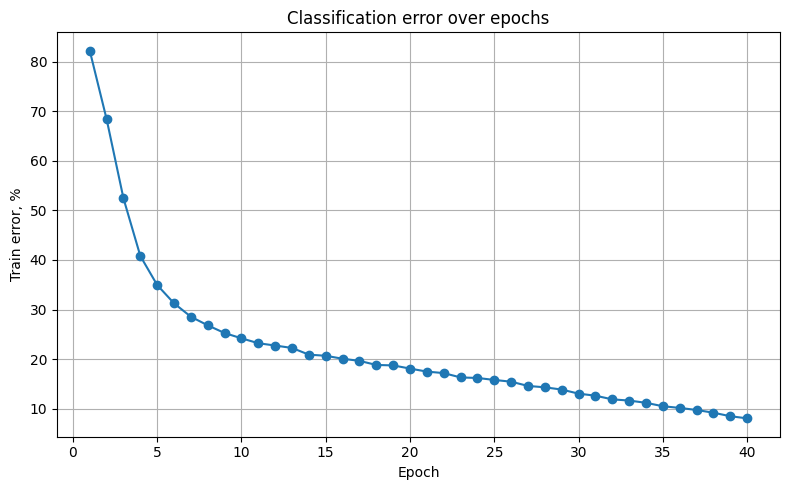

In [20]:
import time
import matplotlib.pyplot as plt

train_errors = []

for epoch in range(40):
    start = time.time()

    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for x, y in trainloader:

      x, y = x.to(device), y.to(device)
      optimizer.zero_grad()
      outputs = model(x)
      loss = criterion(outputs, y)
      loss.backward()
      optimizer.step()

      running_loss += loss.item() * x.size(0)
      correct += (outputs.argmax(1) == y).sum().item()
      total += x.size(0)

    epoch_time = time.time() - start

    epoch_loss = running_loss / total
    epoch_acc = correct / total
    train_errors.append(1 - epoch_acc)

    scheduler.step()

    print(f"Epoch {epoch+1}: loss={epoch_loss:.4f}, "
          f"acc={epoch_acc*100:.2f}%, "
          f"err={(1-epoch_acc)*100:.2f}%, "
          f"time={epoch_time:.1f}s")

# ---------- График ----------
plt.figure(figsize=(8, 5))
plt.plot(range(1, len(train_errors) + 1),
         [e * 100 for e in train_errors],
         marker='o')
plt.xlabel('Epoch')
plt.ylabel('Train error, %')
plt.title('Classification error over epochs')
plt.grid(True)
plt.tight_layout()
plt.show()

In [21]:
@torch.no_grad()
def evaluate(loader):
    model.eval()
    correct = 0
    total = 0

    for x, y in loader:
      x, y = x.to(device), y.to(device)
      outputs = model(x)
      correct += (outputs.argmax(1) == y).sum().item()
      total += x.size(0)

    return correct / total

test_acc = evaluate(testloader)
test_err = 1 - test_acc

print(f"Test accuracy: {test_acc*100:.2f}%")
print(f"Test error:    {test_err*100:.2f}%")

Test accuracy: 89.40%
Test error:    10.60%
